        # Lesson 8.9 · Transformers: Attention Is All You Need
        ### Scaled dot-product attention, multi-head attention, positional encoding, masks and the Transformer encoder

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lessons 8.3, 8.8 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Explain attention as a **soft dictionary look-up** with queries, keys and values, and implement it
- Describe **multi-head** self-attention, **positional encoding** and **causal masks**
- Assemble a **Transformer encoder** and train it on a long-memory task where plain RNNs struggled
- State the **costs and limits** of attention (quadratic memory, data hunger) honestly

> 🌾 **The story so far.** In Lesson 8.8 a recurrent net had to push a one-bit memory through 40 noisy steps, one step at a time. What if every time step could simply **look directly at any other time step**? That is attention: the idea behind modern language models.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import math, torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Attention: a soft dictionary look-up

A Python dictionary maps **keys** to **values**: you present a *query*, find the matching key, and read its value. Attention is the *differentiable, fuzzy* version:

1. compare the **query** with every **key** (dot product = similarity),
2. turn the similarities into **weights** with a softmax (they sum to 1),
3. return the **weighted average of the values**.

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

The $\sqrt{d_k}$ keeps the dot products from growing with the dimension (large values would saturate the softmax and kill gradients).

**Analogy for our cooperative.** To forecast week 40, the *query* asks "what is relevant to a mid-harvest week?". Every past week offers a *key* ("I was a rainy-season week", "I was a shock week") and a *value* (its information).
Attention retrieves a blend of the weeks whose keys match: whether they were 2 or 200 weeks ago. **Distance costs nothing**: every position is one step away from every other.

---
### 🧩 Exercise 1: Implement scaled dot-product attention  ⭐⭐

Write `attention(Q, K, V)` in NumPy. Shapes: `Q (Tq, d)`, `K (Tk, d)`, `V (Tk, dv)`. Return `(out, weights)` where
`weights = softmax(Q @ K.T / sqrt(d))` (softmax over the **last** axis; i.e. across keys; subtract the row max for stability) and `out = weights @ V`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`scores = Q @ K.T / np.sqrt(Q.shape[-1])`: shape `(Tq, Tk)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Stable softmax along `axis=-1`: `e = np.exp(scores - scores.max(-1, keepdims=True)); w = e / e.sum(-1, keepdims=True)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`return w @ V, w`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [2]:
def attention(Q, K, V):
    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    e = np.exp(scores - scores.max(-1, keepdims=True))
    w = e / e.sum(-1, keepdims=True)
    return w @ V, w

rng = np.random.default_rng(0)
Qa, Ka, Va = rng.normal(size=(4, 8)), rng.normal(size=(5, 8)), rng.normal(size=(5, 6))
out_mine, w_mine = attention(Qa, Ka, Va)
print(out_mine.shape, w_mine.shape, w_mine.sum(-1).round(3))

(4, 6) (4, 5) [1. 1. 1. 1.]


In [3]:
ref = F.scaled_dot_product_attention(torch.tensor(Qa)[None], torch.tensor(Ka)[None], torch.tensor(Va)[None])[0].numpy()
ag.check("output shape (4, 6) and weights (4, 5)", out_mine is not None and out_mine.shape == (4, 6) and w_mine.shape == (4, 5))
ag.check("each query's weights sum to 1", w_mine is not None and np.allclose(w_mine.sum(-1), 1))
ag.check("matches PyTorch's scaled_dot_product_attention", out_mine is not None and np.allclose(out_mine, ref, atol=1e-6))

✅  output shape (4, 6) and weights (4, 5)
✅  each query's weights sum to 1
✅  matches PyTorch's scaled_dot_product_attention


True

## 2 · Self-attention and multiple heads

In **self-attention** the queries, keys and values all come from the *same* sequence $X$ (shape `(T, d_model)`), through three learned linear maps:
$Q=XW_Q,\ K=XW_K,\ V=XW_V$. Every position gathers information from every other position, in parallel: no recurrence, so training parallelises beautifully on GPUs.

**Multi-head attention** runs $h$ attention operations side-by-side, each in a smaller subspace ($d_k=d_\text{model}/h$), then concatenates and mixes the results with $W_O$.
Different heads can specialise: one tracks "same season last year", another "recent trend", another "shock events".

output: (1, 6, 8) | attention weights per head: (1, 2, 6, 6)


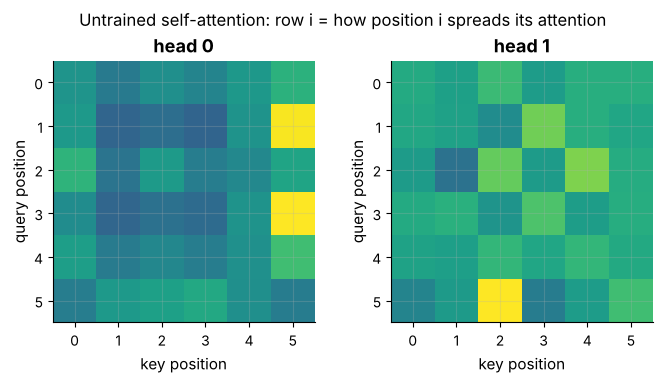

parameters: 288 (= 4·d² + 4·d for d = 8 )


In [4]:
torch.manual_seed(0)
T, d = 6, 8
X = torch.randn(1, T, d)
mha = nn.MultiheadAttention(d, num_heads=2, batch_first=True)
out, w = mha(X, X, X, need_weights=True, average_attn_weights=False)          # w: (batch, heads, T, T)
print("output:", tuple(out.shape), "| attention weights per head:", tuple(w.shape))
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for h in range(2):
    im = axes[h].imshow(w[0, h].detach(), cmap="viridis", vmin=0); axes[h].set(title=f"head {h}", xlabel="key position", ylabel="query position")
plt.suptitle("Untrained self-attention: row i = how position i spreads its attention", y=1.03); plt.show()
print("parameters:", sum(p.numel() for p in mha.parameters()), "(= 4·d² + 4·d for d =", d, ")")

---
### 🧩 Exercise 2: Count attention parameters and scores  ⭐

For `d_model = 32` and 4 heads: (1) compute `n_params_formula` = $4d^2+4d$ (Q, K, V, output projections, each $d\times d$ plus biases) and compare with the real count of `nn.MultiheadAttention(32, 4)` in `n_params_real`;
(2) the attention matrix has $T\times T$ scores per head: set `scores_t100 = ` number of scores (per head) for a sequence of length 100 and `scores_t1000` for length 1000, and `growth = scores_t1000 / scores_t100`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`4 * 32**2 + 4 * 32`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`sum(p.numel() for p in nn.MultiheadAttention(32, 4).parameters())`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Scores are `T*T`: 10,000 and 1,000,000; the ratio is 100 although the length grew only 10×: *quadratic* cost.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [5]:
n_params_formula = 4 * 32 ** 2 + 4 * 32
n_params_real = sum(p.numel() for p in nn.MultiheadAttention(32, 4).parameters())
scores_t100, scores_t1000 = 100 * 100, 1000 * 1000
growth = scores_t1000 / scores_t100
print(n_params_formula, n_params_real, growth)

4224 4224 100.0


In [6]:
ag.check("formula equals the real count (4,224)", n_params_formula == n_params_real == 4224)
ag.check("a 10x longer sequence needs 100x more attention scores", growth == 100)

✅  formula equals the real count (4,224)
✅  a 10x longer sequence needs 100x more attention scores


True

---
## 3 · Positional encoding: attention has no sense of order

Self-attention treats its input as a **set**: permute the positions and each output is simply permuted too (*permutation equivariance*). A Transformer that sees only values can't tell week 1 from week 52!
Fix: **add a position signal** to each input vector. Vaswani et al. used sinusoids of different frequencies:

$$PE_{(p,2i)}=\sin\!\left(\frac{p}{10000^{2i/d}}\right),\qquad PE_{(p,2i+1)}=\cos\!\left(\frac{p}{10000^{2i/d}}\right)$$

Each position gets a unique "barcode"; nearby positions have similar codes; relative offsets are easy to compute from them.
First let's *prove* the problem:

In [7]:
torch.manual_seed(1)
mha = nn.MultiheadAttention(8, 2, batch_first=True).eval()
X = torch.randn(1, 6, 8); perm = torch.tensor([3, 0, 5, 1, 4, 2])
with torch.no_grad():
    out = mha(X, X, X)[0]; out_perm = mha(X[:, perm], X[:, perm], X[:, perm])[0]
print("permuting the input just permutes the output (no position awareness):", torch.allclose(out[:, perm], out_perm, atol=1e-5))

permuting the input just permutes the output (no position awareness): True


---
### 🧩 Exercise 3: Sinusoidal positional encoding  ⭐⭐

Implement `pos_encoding(T, d)` returning a `(T, d)` NumPy array (`d` even) with
`PE[p, 2i] = sin(p / 10000**(2i/d))` and `PE[p, 2i+1] = cos(p / 10000**(2i/d))`. Store the encoding for `T=50, d=16` in `PE`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`pos = np.arange(T)[:, None]`; `i = np.arange(0, d, 2)[None, :]` are the even indices 2i.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`angle = pos / 10000 ** (i / d)` has shape `(T, d/2)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`PE = np.zeros((T, d)); PE[:, 0::2] = np.sin(angle); PE[:, 1::2] = np.cos(angle)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

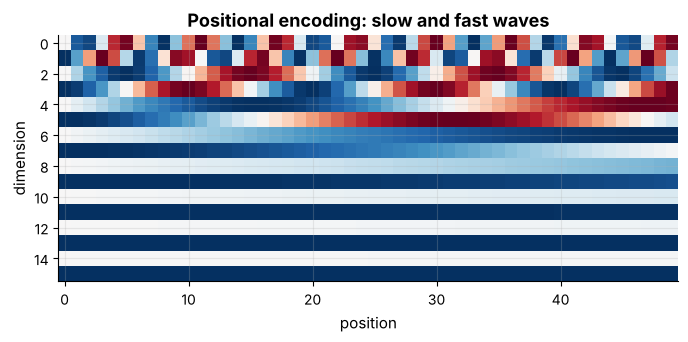

In [8]:
def pos_encoding(T, d):
    pos = np.arange(T)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angle = pos / 10000 ** (i / d)
    pe = np.zeros((T, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

PE = pos_encoding(50, 16)
plt.figure(figsize=(8, 3.2)); plt.imshow(PE.T, aspect="auto", cmap="RdBu"); plt.xlabel("position"); plt.ylabel("dimension"); plt.title("Positional encoding: slow and fast waves"); plt.show()

In [9]:
ag.check("shape (50, 16)", PE is not None and PE.shape == (50, 16))
ag.check("position 0 is [0,1,0,1,...]", PE is not None and np.allclose(PE[0, 0::2], 0) and np.allclose(PE[0, 1::2], 1))
ag.check("PE[5, 2] follows the formula", PE is not None and np.isclose(PE[5, 2], np.sin(5 / 10000 ** (2 / 16))))
ag.check("every position has a unique code", PE is not None and len({tuple(r.round(6)) for r in PE}) == 50)

✅  shape (50, 16)
✅  position 0 is [0,1,0,1,...]
✅  PE[5, 2] follows the formula
✅  every position has a unique code


True

---
## 4 · Masks: controlling who may look at whom

- **Padding mask**: ignore padded (empty) positions in batches of different lengths.
- **Causal (look-ahead) mask**: when *generating* or forecasting step by step, position $t$ may attend only to positions $\le t$. Implemented by setting the forbidden scores to $-\infty$ *before* the softmax, so their weights become exactly 0.

```
allowed (1) / blocked (0) for T=4:        row = query, column = key
    1 0 0 0
    1 1 0 0
    1 1 1 0
    1 1 1 1
```
For a model that reads a *historical window* and predicts the future (our encoder-only forecaster), the whole window is already in the past, so no causal mask is needed inside the window. For a decoder that generates the forecast autoregressively, it is essential.

---
### 🧩 Exercise 4: Causal attention weights  ⭐⭐

Write `causal_weights(Q, K)` returning the `(T, T)` attention-weight matrix (NumPy) where position `t` may only attend to positions `<= t`:
compute scaled scores, set the strictly-upper-triangular entries to `-inf` (`np.triu(np.ones((T,T)), k=1)` marks them), then softmax each row.
Apply it to random `Qc, Kc` of shape `(5, 4)` and store the result in `Wc`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`scores = Q @ K.T / np.sqrt(d)`; `scores[np.triu(np.ones_like(scores), k=1) == 1] = -np.inf`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`np.exp(-inf) = 0`, so blocked positions get zero weight, but subtract the row max first (the diagonal is always finite).

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Row 0 must be `[1, 0, 0, 0, 0]`: the first position can only look at itself.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [10]:
def causal_weights(Q, K):
    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    scores[np.triu(np.ones_like(scores), k=1) == 1] = -np.inf
    e = np.exp(scores - scores.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

rng = np.random.default_rng(1)
Qc, Kc = rng.normal(size=(5, 4)), rng.normal(size=(5, 4))
Wc = causal_weights(Qc, Kc)
print(Wc.round(2))

[[1.   0.   0.   0.   0.  ]
 [0.83 0.17 0.   0.   0.  ]
 [0.51 0.16 0.32 0.   0.  ]
 [0.19 0.55 0.07 0.19 0.  ]
 [0.13 0.34 0.12 0.13 0.28]]


In [11]:
ag.check("rows sum to 1", Wc is not None and np.allclose(Wc.sum(-1), 1))
ag.check("no attention to the future (upper triangle is 0)", Wc is not None and np.allclose(np.triu(Wc, k=1), 0))
ag.check("the first position attends only to itself", Wc is not None and np.isclose(Wc[0, 0], 1))

✅  rows sum to 1
✅  no attention to the future (upper triangle is 0)
✅  the first position attends only to itself


True

---
## 5 · The Transformer encoder block

```
x ─► [ Multi-Head Self-Attention ] ─► + ─► LayerNorm ─► [ Feed-forward: Linear–ReLU–Linear ] ─► + ─► LayerNorm ─► out
└──────────── residual ────────────┘                   └───────────────── residual ───────────┘
```

| Ingredient | Why |
|---|---|
| **Residual connections** | give gradients a direct highway; allow very deep stacks |
| **LayerNorm** | stabilises activations per position (unlike batch-norm it doesn't depend on the batch) |
| **Feed-forward network** | per-position non-linear processing after the mixing step |
| **Stacking** $N$ blocks | repeated *communication* (attention) then *computation* (FFN) |
| **Warm-up + AdamW** | Transformers are touchy about learning rates |

In PyTorch: `nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward, dropout, batch_first=True)` wrapped in `nn.TransformerEncoder(layer, num_layers)`.

## 6 · Showdown: the long-memory task again
Same task as Lesson 8.8: a **weak signal (±0.5)** at step 0, noise N(0,1) afterwards, label = its sign. That lesson's winners needed a special LSTM initialisation; the others failed.
To classify, we prepend a learnable **[CLS] token** whose final output feeds a linear layer: it learns to *ask* "where is the signal?"; positional encoding lets it find *position 0*.

In [12]:
def make_memory_task(n, T, seed, amp=0.5):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, T, 1, generator=g); sig = (torch.rand(n, generator=g) > 0.5).float() * 2 - 1
    x[:, 0, 0] = sig * amp
    return x, (sig > 0).long()

def pos_enc_t(T, d):
    pe = torch.zeros(T, d); pos = torch.arange(T).float()[:, None]; div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

class TransformerClassifier(nn.Module):
    def __init__(self, T, d=32, heads=4, layers=2, use_pe=True):
        super().__init__()
        self.inp, self.use_pe = nn.Linear(1, d), use_pe
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.register_buffer("pe", pos_enc_t(T + 1, d))
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 64, 0.0, batch_first=True), layers)
        self.out = nn.Linear(d, 2)
    def tokens(self, x):
        z = torch.cat([self.cls.expand(len(x), -1, -1), self.inp(x)], 1)
        return z + self.pe if self.use_pe else z
    def forward(self, x):
        return self.out(self.enc(self.tokens(x))[:, 0])              # read the [CLS] position

def run_tf(T, seed=0, use_pe=True, epochs=30, lr=2e-3):
    torch.manual_seed(seed)
    Xtr, ytr = make_memory_task(1500, T, 1); Xte, yte = make_memory_task(500, T, 2)
    m = TransformerClassifier(T, use_pe=use_pe); opt = torch.optim.Adam(m.parameters(), lr=lr); lossf = nn.CrossEntropyLoss()
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]; opt.zero_grad(); lossf(m(Xtr[idx]), ytr[idx]).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    m.eval()
    with torch.no_grad(): return m, (m(Xte).argmax(1) == yte).float().mean().item()

results = {}
for name, kw in [("Transformer, T=40", dict(T=40)), ("Transformer WITHOUT positional encoding, T=40", dict(T=40, use_pe=False))]:
    accs = []
    for s in range(3):
        m_, a_ = run_tf(seed=s, **kw); accs.append(a_)
        if name == "Transformer, T=40" and s == 0: model_t40 = m_
    results[name] = accs
pd.DataFrame(results, index=[f"seed {s}" for s in range(3)]).T.round(2)

,seed 0,seed 1,seed 2
"Transformer, T=40",1.00,1.00,1.00
"Transformer WITHOUT positional encoding, T=40",0.71,0.58,0.49


Compare with Lesson 8.8 on the *identical* task: plain RNN erratic, GRU/default-LSTM stuck at chance, only a specially-initialised LSTM reliable.
The Transformer solves it **without any special initialisation**: position 0 is just one attention hop away from [CLS]: and **without positional encoding it stays near chance or only modestly above it** (0.49–0.71 across seeds): it sees the signal but can't tell *which* of the 41 tokens it is.

### What did it attend to?

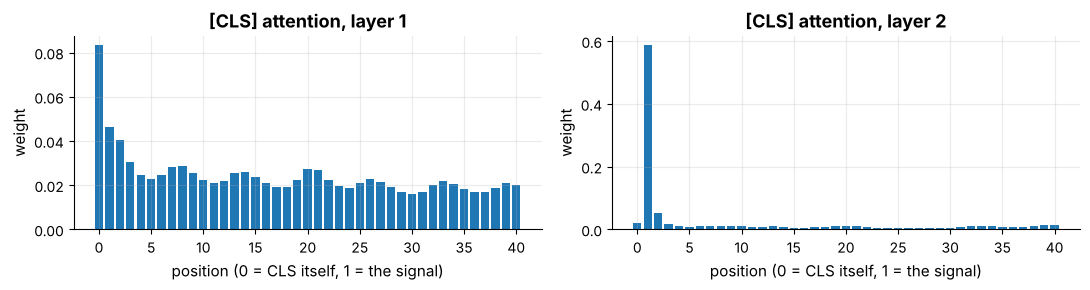

share of [CLS] attention on the signal position (token 1): layer 1 = 0.05, layer 2 = 0.59   (uniform would be 0.024)


In [13]:
m = model_t40.eval(); Xv, yv = make_memory_task(200, 40, 3)
with torch.no_grad():
    z = m.tokens(Xv); attn_maps = []
    for layer in m.enc.layers:
        _, w = layer.self_attn(z, z, z, need_weights=True, average_attn_weights=True)       # (batch, T+1, T+1)
        attn_maps.append(w[:, 0].mean(0).numpy())                                            # attention FROM the [CLS] token, averaged over samples
        z = layer(z)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, a, name in zip(axes, attn_maps, ["layer 1", "layer 2"]):
    ax.bar(range(len(a)), a); ax.set(title=f"[CLS] attention, {name}", xlabel="position (0 = CLS itself, 1 = the signal)", ylabel="weight")
plt.tight_layout(); plt.show()
print("share of [CLS] attention on the signal position (token 1): layer 1 = %.2f, layer 2 = %.2f   (uniform would be %.3f)" % (attn_maps[0][1], attn_maps[1][1], 1 / 41))

Look at the share of attention placed on token 1 relative to the uniform baseline 1/41 ≈ 0.024. Attention maps are a **window** into the model: suggestive, not a complete explanation
(heads, layers and residual paths all contribute), but a very useful debugging tool.

### Distance costs nothing: and nothing is free

In [14]:
import time; t0 = time.time()
_, acc100 = run_tf(100, seed=0)
print(f"T = 100 (a gap of 99 noisy steps): Transformer test accuracy = {acc100:.2f}   [{time.time()-t0:.0f}s]")

T = 100 (a gap of 99 noisy steps): Transformer test accuracy = 1.00   [32s]


| Strength | Cost / limit |
|---|---|
| any two positions interact in **one** step (no vanishing path) | attention memory and compute grow as **$O(T^2)$**: 10× longer sequence = 100× cost |
| fully **parallel** over time on GPUs | needs **explicit position information** |
| scales spectacularly with data and compute | **data-hungry**: with a few hundred rows (a single price series) it often loses to simple models: see Lesson 7.7 |
| flexible: text, images (ViT), audio, tables, time series | many hyper-parameters; sensitive to learning-rate warm-up |

**For forecasting specifically:** Transformer variants (Informer, Autoformer, PatchTST, Temporal Fusion Transformer…) work best with **many series and long histories**.
For one weekly price series, a well-featured linear model or boosted trees is a strong first choice; you'll test a Transformer forecaster yourself in the capstone.

## 7 · A forecasting-shaped Transformer (preview of Project 4)
The skeleton for a window → horizon forecaster: linear-project each week's features to `d_model`, add positional encoding, run `nn.TransformerEncoder`, **pool** (mean or last token), then a linear head to *H* outputs.

In [15]:
class TSTransformer(nn.Module):
    def __init__(self, n_feat, lookback, horizon, d=32, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(n_feat, d); self.register_buffer("pe", pos_enc_t(lookback, d))
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 4 * d, dropout, batch_first=True), layers)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, horizon))
    def forward(self, x):                                    # x: (batch, lookback, n_feat)
        z = self.enc(self.proj(x) + self.pe)
        return self.head(z.mean(dim=1))                       # average over time, then predict all horizons at once

ts = TSTransformer(n_feat=4, lookback=52, horizon=8)
print("output shape:", tuple(ts(torch.randn(16, 52, 4)).shape), "| parameters:", f"{sum(p.numel() for p in ts.parameters()):,}")

output shape: (16, 8) | parameters: 25,832


## 🎓 Mini-quiz
1. Why divide by $\sqrt{d_k}$ in attention?
2. A Transformer is given a sentence with its words shuffled and *no positional encoding*. What happens to the output set?
3. Doubling the sequence length multiplies attention cost by…?
4. Where would you use a causal mask?

<details><summary>Answers</summary>

1. Dot products of $d_k$-dimensional vectors have variance ∝ $d_k$; scaling keeps the softmax out of its saturated, zero-gradient regime. 2. The outputs are the same vectors, just permuted: the model can't tell the order. 3. 4× (quadratic). 4. When generating/forecasting autoregressively so a position cannot peek at future positions (decoder self-attention; training language models).
</details>

        ---
        ## 🧾 Recap
        - **Attention** = softmax(QKᵀ/√d)·V: a soft look-up in which every position can read every other in one step.
- **Multi-head** attention learns several kinds of relationships in parallel; **positional encoding** injects order; **masks** control visibility.
- A **Transformer encoder block** = attention + feed-forward, each with residual connection and LayerNorm.
- It solved a long-memory task that defeated plain RNNs, but costs **O(T²)** and wants lots of data.

**Next up:** Lesson 8.10; Keras and TensorFlow: the same ideas in another framework (a side-by-side 'Rosetta stone').